# Measuring portfolio sensitivity to estimation error

A small matrix error can be magnified by covariance inversion:

$$
\frac{\lVert(\Sigma+\Delta)^{-1}-\Sigma^{-1}\rVert_2}{\lVert\Sigma^{-1}\rVert_2}
\leq
\frac{\kappa_2(\Sigma)\varepsilon}{1-\kappa_2(\Sigma)\varepsilon},
\qquad
\varepsilon=\frac{\lVert\Delta\rVert_2}{\lVert\Sigma\rVert_2},
\qquad
\kappa_2(\Sigma)\varepsilon<1.
$$

Here, $\Sigma$ is a positive-definite covariance matrix, $\Delta$ is a covariance error, $\lVert\cdot\rVert_2$ is the spectral norm, $\varepsilon$ is the relative error size, and $\kappa_2(\Sigma)$ is the spectral condition number. The final condition is required for the finite bound shown.

,Quantity,Value
0,Blocks,5
1,Assets per block,6
2,Assets,30
3,Within-block correlation,0.600000
4,Observations,250
5,Observation to asset ratio,8.333333
6,Random seed,42


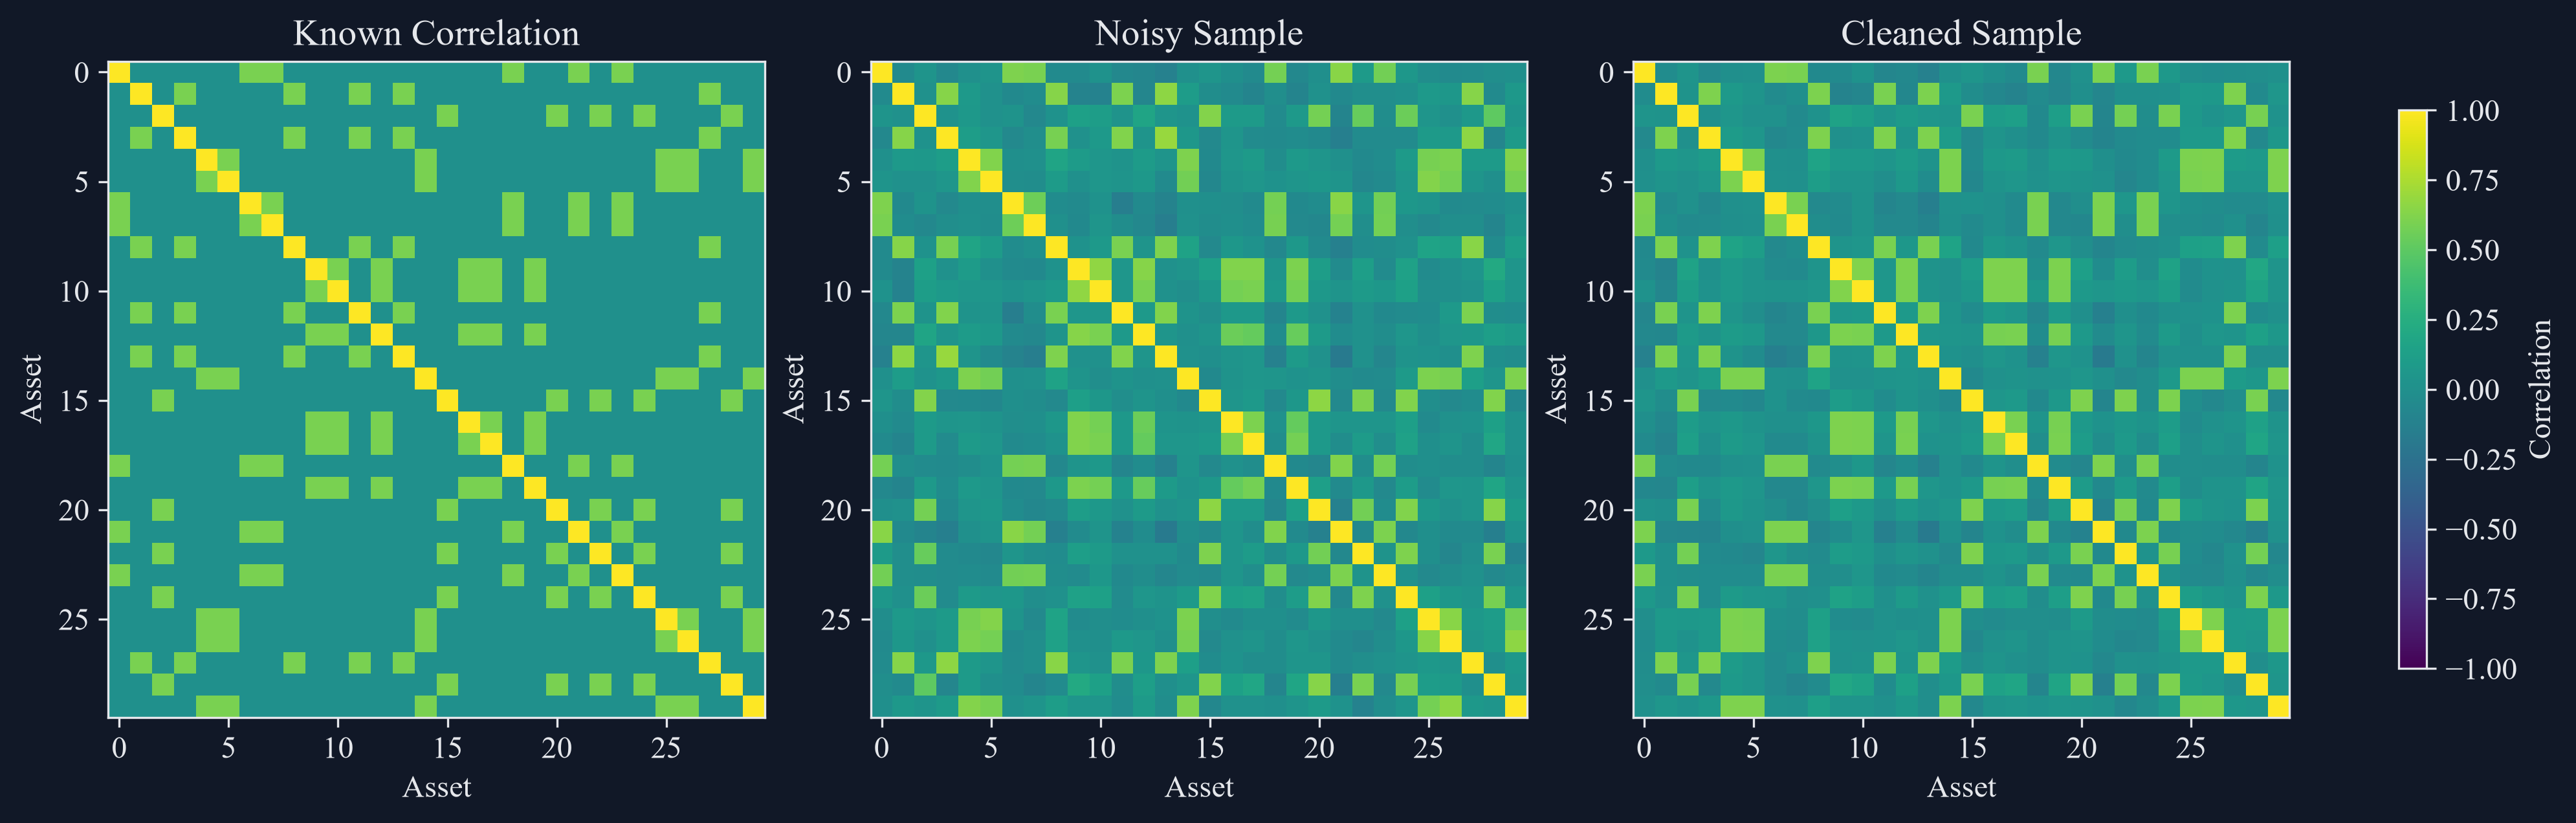

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov
from RiskLabAI.data.synthetic_data import form_true_matrix, simulates_cov_mu
from RiskLabAI.optimization import get_optimal_portfolio_weights
FIGURES = ROOT / 'outputs' / 'figures' / '23_portfolio_geometry'
TABLES = ROOT / 'outputs' / 'tables' / '23_portfolio_geometry'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def global_minimum_variance(covariance):
    inverse_ones = np.linalg.solve(covariance, np.ones(covariance.shape[0]))
    return inverse_ones / inverse_ones.sum()

def mean_return_weighted(covariance, expected_return):
    direction = np.linalg.solve(covariance, np.asarray(expected_return, dtype=float))
    return direction / direction.sum()

def inverse_variance(covariance):
    weights = 1.0 / np.diag(covariance)
    return weights / weights.sum()

def _refine_long_only_variance(covariance, weights):
    """Refine a feasible portfolio by solving its active-face optimality equations."""
    weights = np.maximum(np.asarray(weights, dtype=float), 0.0)
    weights /= weights.sum()
    free = np.ones(len(weights), dtype=bool)
    for iteration in range(2000):
        indices = np.flatnonzero(free)
        direction = np.linalg.solve(covariance[np.ix_(indices, indices)], np.ones(len(indices)))
        candidate = np.zeros(len(weights))
        candidate[indices] = direction / direction.sum()
        negative = indices[candidate[indices] < 0.0]
        if len(negative):
            ratios = weights[negative] / (weights[negative] - candidate[negative])
            position = int(np.argmin(ratios))
            weights += ratios[position] * (candidate - weights)
            weights = np.maximum(weights, 0.0)
            pivot = negative[position]
            weights[pivot] = 0.0
            free[pivot] = False
            continue
        weights = candidate
        marginal = covariance @ weights
        multiplier = float(weights @ marginal)
        inactive = np.flatnonzero(~free)
        if not len(inactive) or np.min(marginal[inactive]) >= multiplier:
            return weights
        free[inactive[int(np.argmin(marginal[inactive]))]] = True
    raise RuntimeError("Long-only optimality refinement did not converge")


def _refine_norm_limited_variance(covariance, squared_norm_limit):
    """Solve the existing squared-norm constraint through its ridge multiplier."""
    count = len(covariance)
    if squared_norm_limit < 1.0 / count:
        raise ValueError("norm limit is infeasible")
    if squared_norm_limit == 1.0 / count:
        return np.repeat(1.0 / count, count)
    unrestricted = global_minimum_variance(covariance)
    if float(unrestricted @ unrestricted) <= squared_norm_limit:
        return unrestricted
    scaled = covariance / np.max(np.abs(covariance))
    identity = np.eye(count)
    lower, upper = 0.0, 1.0
    while np.sum(global_minimum_variance(scaled + upper * identity)**2) > squared_norm_limit:
        upper *= 2.0
    weights = global_minimum_variance(scaled + upper * identity)
    for iteration in range(100):
        middle = (lower + upper) / 2.0
        candidate = global_minimum_variance(scaled + middle * identity)
        if float(candidate @ candidate) > squared_norm_limit:
            lower = middle
        else:
            upper, weights = middle, candidate
    return weights


def long_only_minimum_variance(covariance):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method='SLSQP', bounds=[(0.0, 1.0)] * asset_count, constraints=[{'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0, 'jac': lambda weights: np.ones(asset_count)}], options={'ftol': 1e-12, 'maxiter': 2000})
    assert result.success
    return _refine_long_only_variance(covariance, result.x)

def norm_limited_minimum_variance(covariance, squared_norm_limit):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    constraints = [{'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0, 'jac': lambda weights: np.ones(asset_count)}, {'type': 'ineq', 'fun': lambda weights: squared_norm_limit - float(weights @ weights), 'jac': lambda weights: -2.0 * weights}]
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method='SLSQP', constraints=constraints, options={'ftol': 1e-12, 'maxiter': 3000})
    assert result.success
    return _refine_norm_limited_variance(covariance, squared_norm_limit)

def target_return_portfolio(covariance, expected_return, target):
    asset_count = covariance.shape[0]
    constraint_matrix = np.column_stack([np.ones(asset_count), expected_return])
    inverse_constraint = np.linalg.solve(covariance, constraint_matrix)
    middle = constraint_matrix.T @ inverse_constraint
    return inverse_constraint @ np.linalg.solve(middle, np.array([1.0, target]))

def portfolio_record(name, weights, expected_return, covariance):
    weights = np.asarray(weights, dtype=float).reshape(-1)
    return {'Portfolio': name, 'Expected annual return': float(weights @ expected_return), 'Annual volatility': float(np.sqrt(weights @ covariance @ weights)), 'Largest long weight': float(weights.max()), 'Smallest weight': float(weights.min()), 'Gross exposure': float(np.abs(weights).sum()), 'Weight concentration': float(weights @ weights), 'Effective holdings': float(1.0 / (weights @ weights))}
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Industry portfolios'], 'Value': ['49_Industry_Portfolios_daily_CSV.zip', 'Kenneth R. French Data Library', 'Daily value-weighted return', str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), len(industry_returns), industry_returns.shape[1]]})
np.random.seed(42)
block_count = 5
block_size = 6
within_block_correlation = 0.6
observation_count = 250
true_mean, true_covariance = form_true_matrix(block_count, block_size, within_block_correlation)
sample_mean, sample_covariance = simulates_cov_mu(true_mean, true_covariance, observation_count)
asset_count = true_covariance.shape[0]
observation_asset_ratio = observation_count / asset_count
cleaned_covariance = denoise_cov(sample_covariance, observation_asset_ratio)
true_correlation = cov_to_corr(true_covariance)
sample_correlation = cov_to_corr(sample_covariance)
cleaned_correlation = cov_to_corr(cleaned_covariance)
known_truth_design = pd.DataFrame({'Quantity': ['Blocks', 'Assets per block', 'Assets', 'Within-block correlation', 'Observations', 'Observation to asset ratio', 'Random seed'], 'Value': [block_count, block_size, asset_count, within_block_correlation, observation_count, observation_asset_ratio, 42]})
save_table(known_truth_design, 'known_truth_design', 'Visible design of the controlled block-covariance experiment.', 'tab:chapter20-known-truth-design')
display(known_truth_design)
figure, axes = plt.subplots(1, 3, figsize=(13.2, 4.1), constrained_layout=True)
for axis, matrix, title in zip(axes, [true_correlation, sample_correlation, cleaned_correlation], ['Known Correlation', 'Noisy Sample', 'Cleaned Sample']):
    image = axis.imshow(matrix, cmap='viridis', vmin=-1.0, vmax=1.0)
    axis.set_title(title)
    axis.set_xlabel('Asset')
    axis.set_ylabel('Asset')
figure.colorbar(image, ax=axes, shrink=0.78, label='Correlation')
save_figure(figure, 'true_sample_cleaned_correlations')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Comparing raw covariance with a cleaned estimate

Weight error and variance under the known covariance are measured by:

$$
\operatorname{RMSE}_w(m)
=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(\widehat w_{i,m}-w_{i,0})^2},
\qquad
V_m=\widehat w_m^{\mathsf T}\Sigma_0\widehat w_m,
\qquad
\rho_m=\frac{V_m}{V_0}.
$$

Here, $N$ is the number of assets, $m$ names a covariance estimate, $\widehat w_{i,m}$ is its estimated weight for asset $i$, $w_{i,0}$ is the known optimal weight, $\Sigma_0$ is the covariance used to generate returns, $V_m$ is variance under that known covariance, $V_0$ is the smallest known variance, and $\rho_m$ is the true-variance ratio.

,Matrix,Relative covariance error,Correlation condition number,Smallest correlation eigenvalue
0,Known covariance,0,10,0.400000
1,Sample covariance,0.197270,28.609205,0.170466
2,Cleaned covariance,0.180731,13.160539,0.371333


,Method,Weight root mean squared error,Weight absolute error,True variance,True variance ratio,Gross exposure,Largest absolute weight
0,Known GMV,0,0,0.000572,1,1.594311,0.208659
1,Raw inverse variance,0.044910,1.108898,0.001060,1.853498,1,0.093031
2,Cleaned inverse variance,0.044910,1.108898,0.001060,1.853498,1,0.093031
3,Raw GMV,0.017080,0.403453,0.000611,1.069412,1.639230,0.243490
4,Cleaned GMV,0.011634,0.250562,0.000590,1.031281,1.633716,0.232766


,Preliminary experiment,Chapter 20 result,Chapter routing
0,Known shuffled block covariance,Reproduced,Chapter 20
1,Noisy sample covariance,Reproduced,Chapter 20
2,Marcenko-Pastur cleaning,Reproduced,Chapter 20
3,Inverse-variance portfolios,Reproduced,Chapter 20
4,Raw and cleaned GMV,Reproduced,Chapter 20
5,Known true-variance comparison,Reproduced,Chapter 20


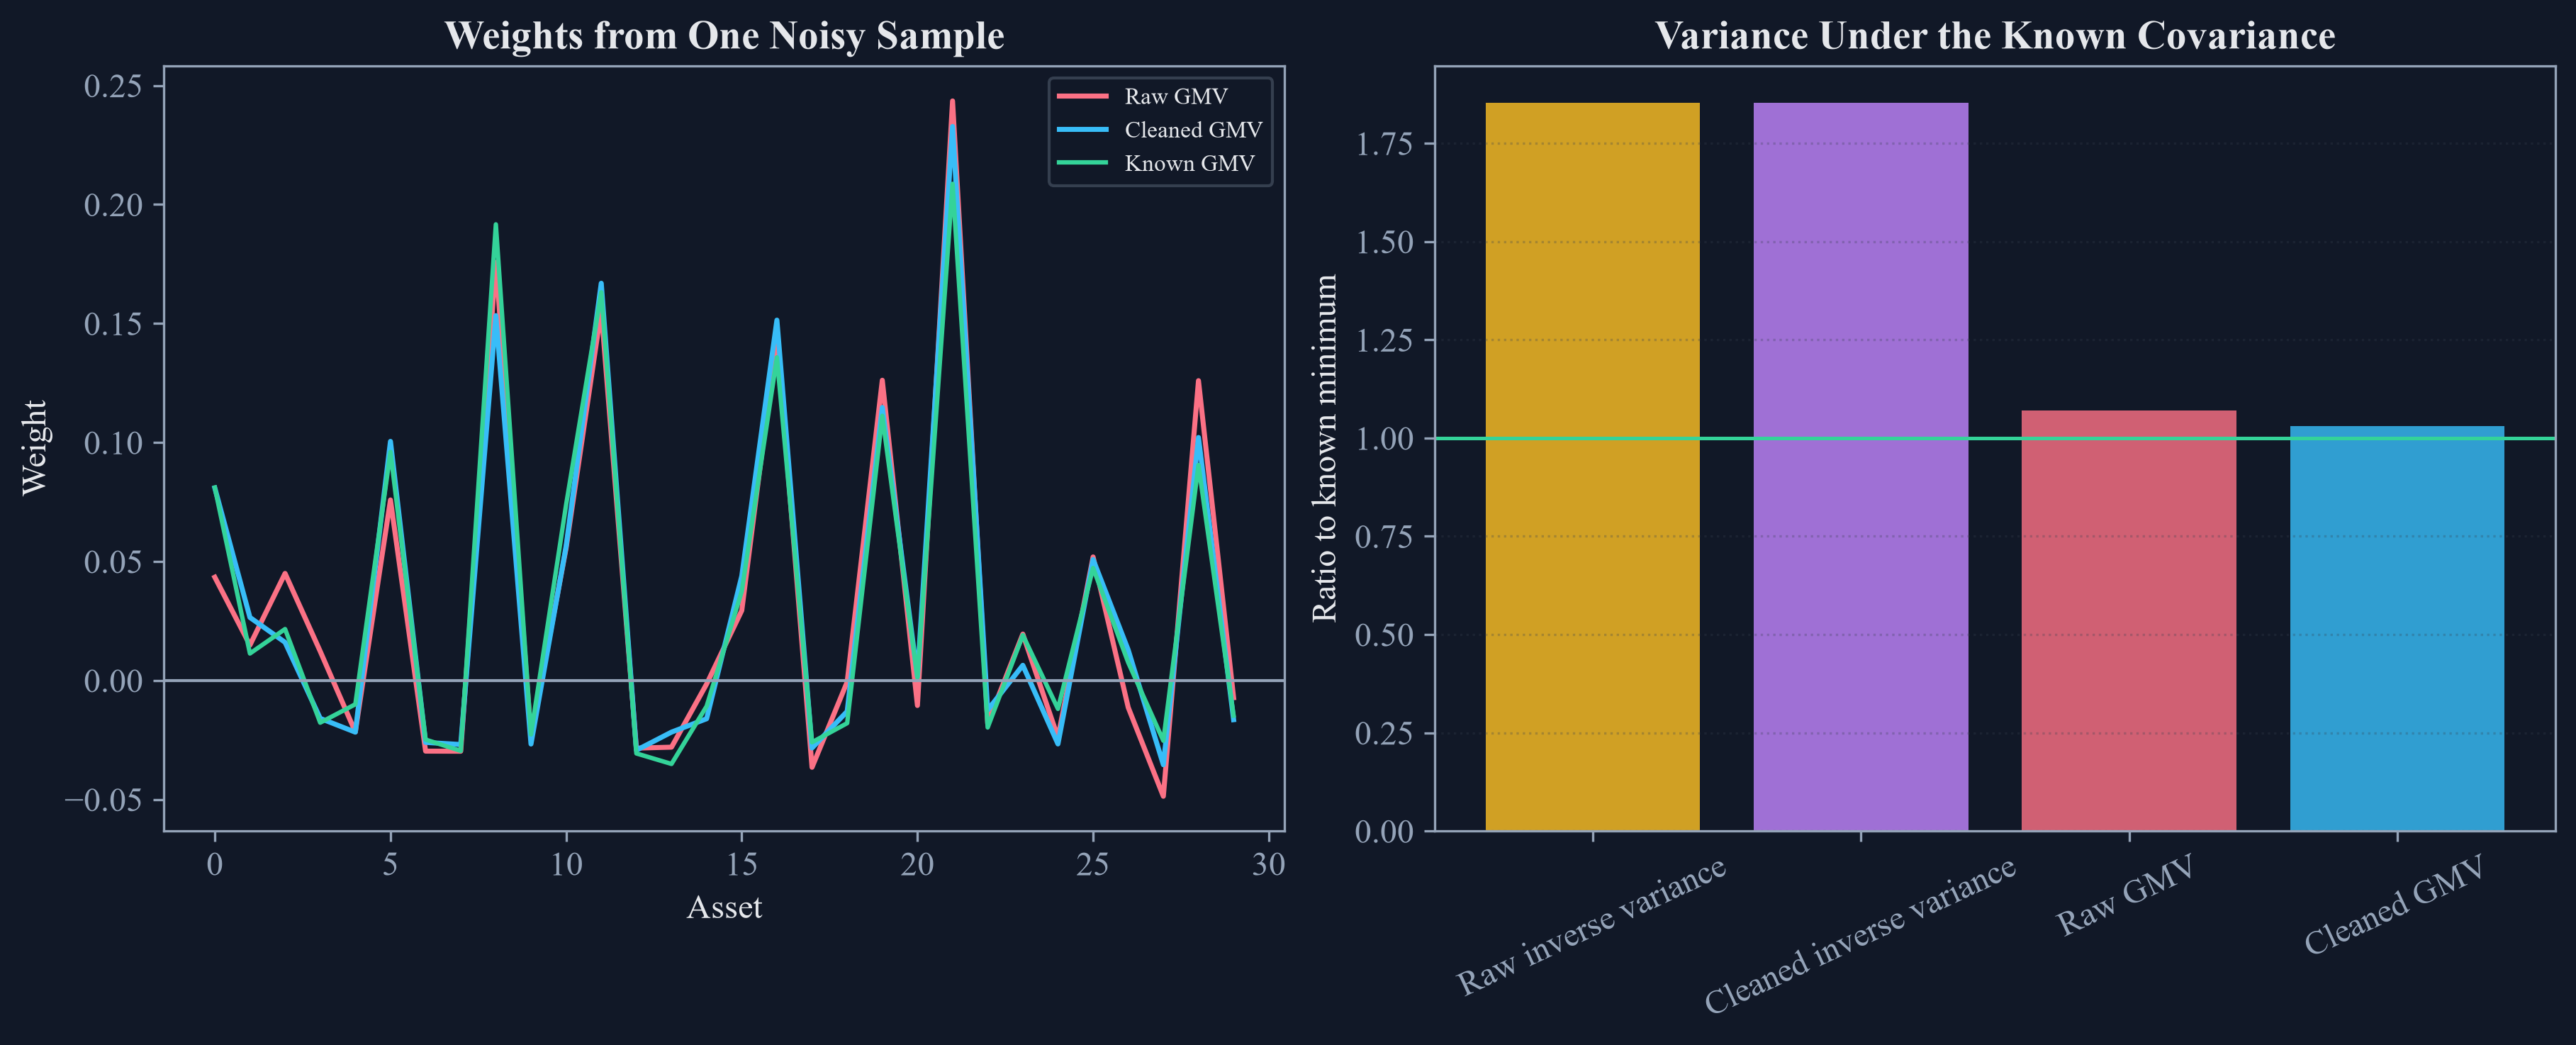

In [2]:
true_gmv = global_minimum_variance(true_covariance)
raw_gmv = get_optimal_portfolio_weights(sample_covariance).reshape(-1)
clean_gmv = get_optimal_portfolio_weights(cleaned_covariance).reshape(-1)
raw_ivp = inverse_variance(sample_covariance)
clean_ivp = inverse_variance(cleaned_covariance)
true_variance_floor = float(true_gmv @ true_covariance @ true_gmv)
one_path_weights = {
    "Known GMV": true_gmv,
    "Raw inverse variance": raw_ivp,
    "Cleaned inverse variance": clean_ivp,
    "Raw GMV": raw_gmv,
    "Cleaned GMV": clean_gmv,
}
one_path_rows = []
for method, weights in one_path_weights.items():
    one_path_rows.append({
        "Method": method,
        "Weight root mean squared error": np.sqrt(np.mean((weights - true_gmv) ** 2)),
        "Weight absolute error": np.sum(np.abs(weights - true_gmv)),
        "True variance": float(weights @ true_covariance @ weights),
        "True variance ratio": float(weights @ true_covariance @ weights) / true_variance_floor,
        "Gross exposure": np.abs(weights).sum(),
        "Largest absolute weight": np.abs(weights).max(),
    })
one_path_portfolio_summary = pd.DataFrame(one_path_rows)
covariance_summary = pd.DataFrame({
    "Matrix": ["Known covariance", "Sample covariance", "Cleaned covariance"],
    "Relative covariance error": [0.0, np.linalg.norm(sample_covariance - true_covariance, ord="fro") / np.linalg.norm(true_covariance, ord="fro"), np.linalg.norm(cleaned_covariance - true_covariance, ord="fro") / np.linalg.norm(true_covariance, ord="fro")],
    "Correlation condition number": [np.linalg.cond(true_correlation), np.linalg.cond(sample_correlation), np.linalg.cond(cleaned_correlation)],
    "Smallest correlation eigenvalue": [np.linalg.eigvalsh(true_correlation).min(), np.linalg.eigvalsh(sample_correlation).min(), np.linalg.eigvalsh(cleaned_correlation).min()],
})
preliminary_reproduction = pd.DataFrame({
    "Preliminary experiment": ["Known shuffled block covariance", "Noisy sample covariance", "Marcenko-Pastur cleaning", "Inverse-variance portfolios", "Raw and cleaned GMV", "Known true-variance comparison"],
    "Chapter 20 result": ["Reproduced", "Reproduced", "Reproduced", "Reproduced", "Reproduced", "Reproduced"],
    "Chapter routing": ["Chapter 20", "Chapter 20", "Chapter 20", "Chapter 20", "Chapter 20", "Chapter 20"],
})
save_table(covariance_summary, "known_truth_covariance_summary", "Known, noisy, and cleaned covariance diagnostics for one controlled sample.", "tab:chapter20-covariance-summary")
save_table(one_path_portfolio_summary, "one_path_portfolio_summary", "Portfolio errors and true risk for one controlled sample.", "tab:chapter20-one-path-summary")
save_table(preliminary_reproduction, "preliminary_portfolio_reproduction", "Chapter 20 coverage of the preliminary portfolio-construction experiment.", "tab:chapter20-preliminary-reproduction")
display(covariance_summary.round(6))
display(one_path_portfolio_summary.round(6))
display(preliminary_reproduction)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), constrained_layout=True)
positions = np.arange(asset_count)
axes[0].plot(positions, raw_gmv, color=palette["rose"], linewidth=1.7, label="Raw GMV")
axes[0].plot(positions, clean_gmv, color=palette["cyan"], linewidth=1.7, label="Cleaned GMV")
axes[0].plot(positions, true_gmv, color=palette["green"], linewidth=1.5, label="Known GMV")
axes[0].axhline(0.0, color=palette["muted"], linewidth=1.0)
axes[0].set_title("Weights from One Noisy Sample")
axes[0].set_xlabel("Asset")
axes[0].set_ylabel("Weight")
axes[0].legend(fontsize=8)
plot_summary = one_path_portfolio_summary.loc[one_path_portfolio_summary["Method"] != "Known GMV"]
axes[1].bar(plot_summary["Method"], plot_summary["True variance ratio"], color=[palette["amber"], palette["violet"], palette["rose"], palette["cyan"]], alpha=0.82)
axes[1].axhline(1.0, color=palette["green"], linewidth=1.2)
axes[1].set_title("Variance Under the Known Covariance")
axes[1].set_ylabel("Ratio to known minimum")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.28)
save_figure(figure, "one_path_weights_true_risk")

## Isolating covariance error from expected-return error

The first-order change in a normalized inverse-covariance portfolio separates covariance and expected-return errors:

$$
d(\Sigma^{-1}\mu)
=-\Sigma^{-1}(d\Sigma)\Sigma^{-1}\mu+\Sigma^{-1}d\mu,
\qquad
dw=d\left(\frac{\Sigma^{-1}\mu}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mu}\right).
$$

Here, $d\Sigma$ is a small covariance change, $d\mu$ is a small expected-return change, $\Sigma^{-1}\mu$ is the unnormalized portfolio direction, and $dw$ is the resulting first-order change after the weights are rescaled to sum to one.

,Stress,Relative input change,Weight absolute change,True variance ratio
0,Covariance blend at 10 percent,0.069086,0.132120,1.011875
1,Covariance blend at 25 percent,0.172716,0.320654,1.069947
2,Covariance blend at 50 percent,0.345432,0.611540,1.254417
3,Mean change at 10 percent,0.100000,8.238794,1.396144
4,Mean change at 25 percent,0.250000,24.751805,2.612776
5,Mean change at 50 percent,0.500000,74.576053,9.701408


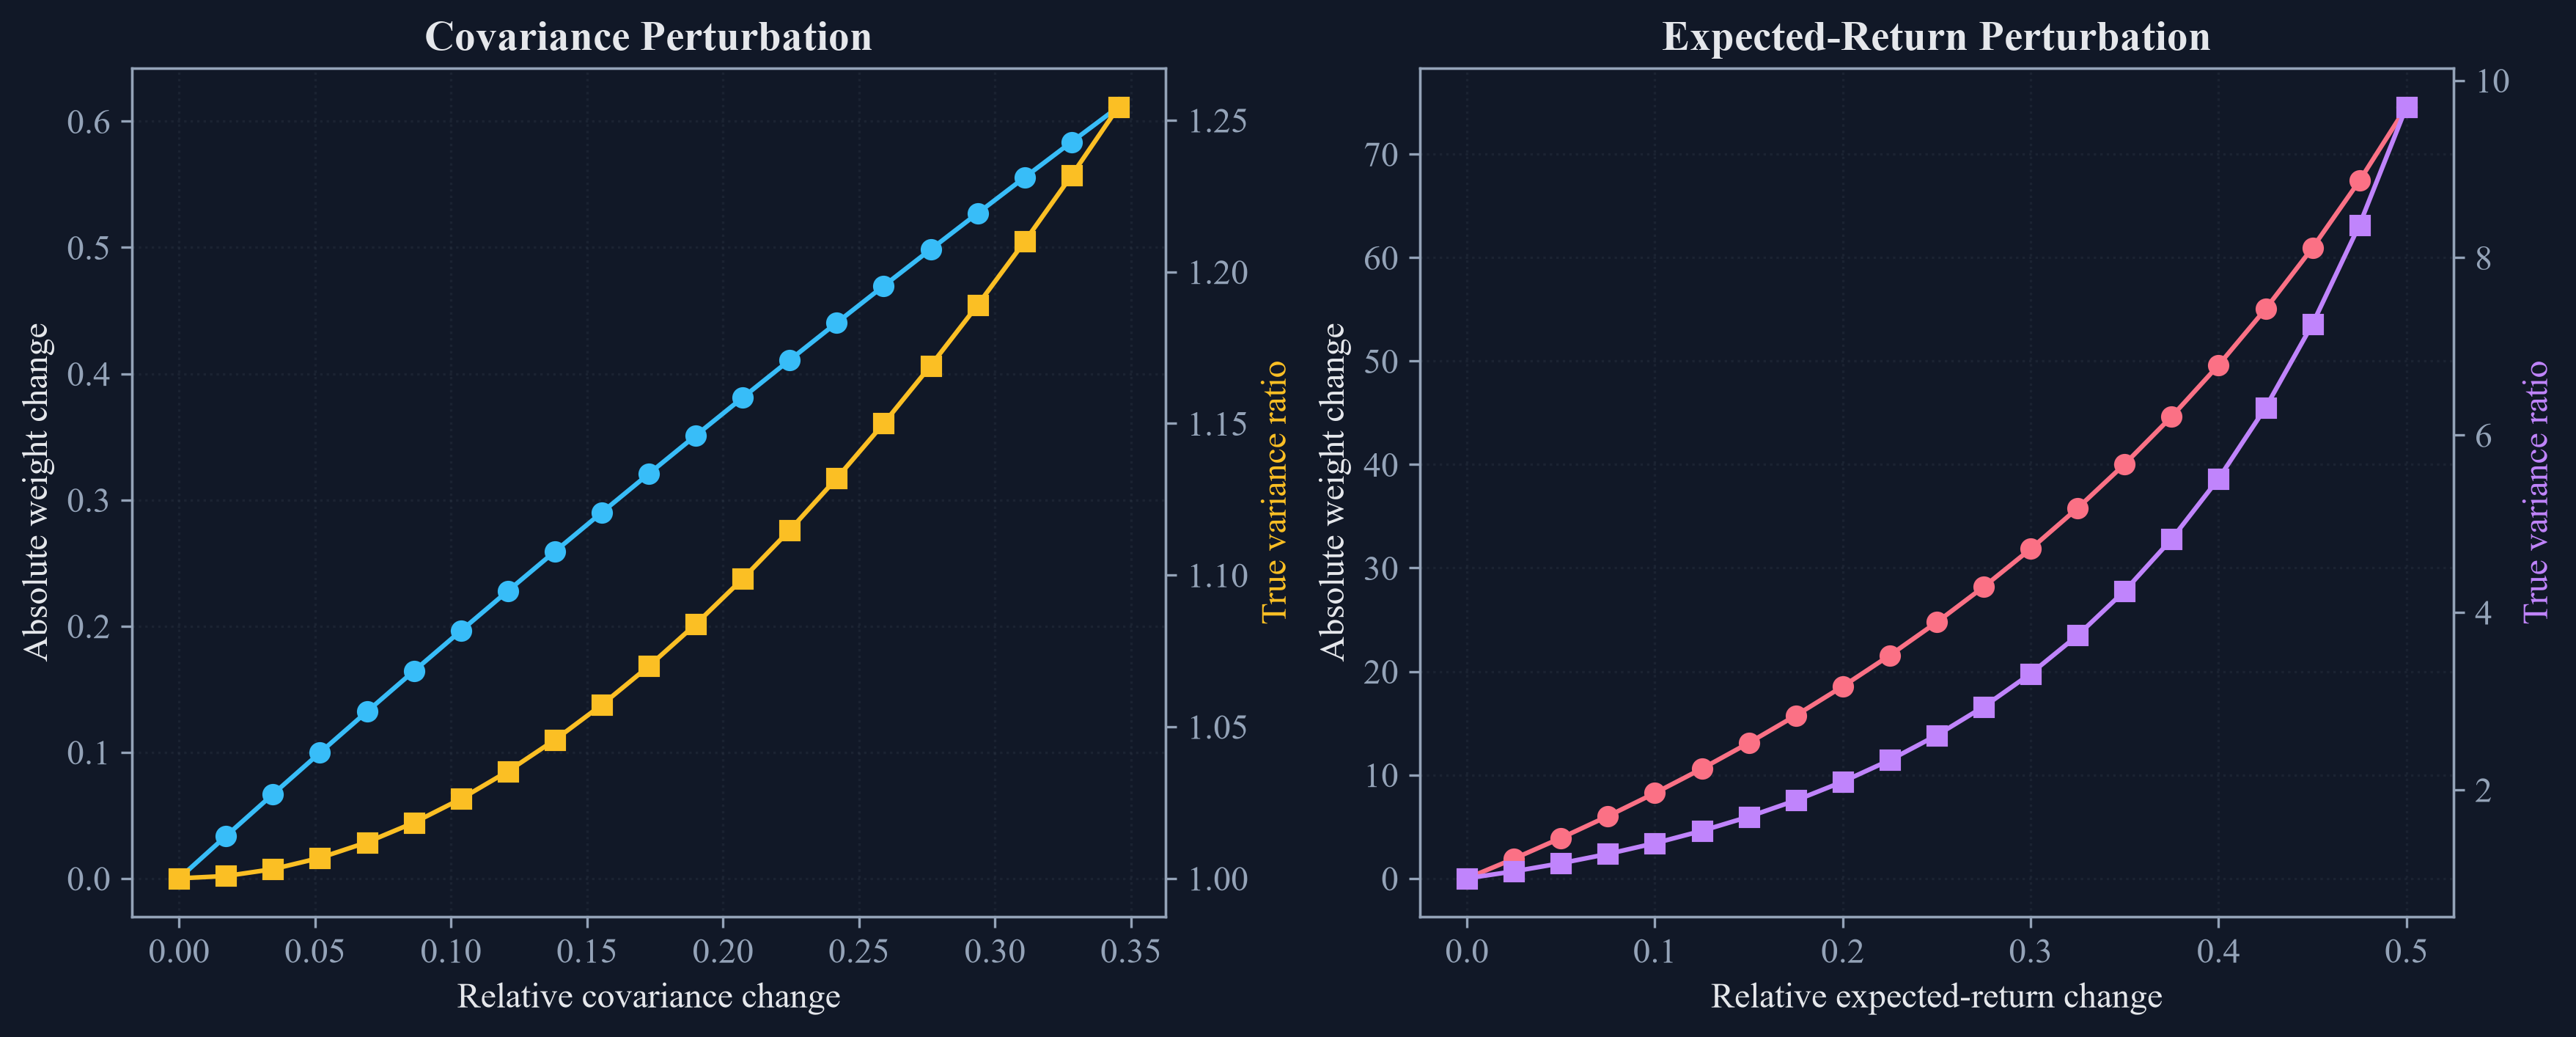

In [3]:
covariance_levels = np.linspace(0.0, 0.50, 21)
covariance_sensitivity_rows = []
diagonal_covariance = np.diag(np.diag(true_covariance))
for level in covariance_levels:
    perturbed_covariance = (1.0 - level) * true_covariance + level * diagonal_covariance
    weights = global_minimum_variance(perturbed_covariance)
    covariance_sensitivity_rows.append({
        "Perturbation level": level,
        "Relative covariance change": np.linalg.norm(perturbed_covariance - true_covariance, ord=2) / np.linalg.norm(true_covariance, ord=2),
        "Condition number": np.linalg.cond(cov_to_corr(perturbed_covariance)),
        "Weight absolute change": np.sum(np.abs(weights - true_gmv)),
        "True variance ratio": float(weights @ true_covariance @ weights) / true_variance_floor,
    })
covariance_sensitivity = pd.DataFrame(covariance_sensitivity_rows)

true_mean_vector = true_mean.reshape(-1)
base_mean_weights = mean_return_weighted(true_covariance, true_mean_vector)
mean_direction = np.linspace(-1.0, 1.0, asset_count)
mean_direction -= mean_direction.mean()
mean_direction /= np.linalg.norm(mean_direction)
mean_levels = np.linspace(0.0, 0.50, 21)
mean_sensitivity_rows = []
for level in mean_levels:
    perturbed_mean = true_mean_vector + level * np.linalg.norm(true_mean_vector) * mean_direction
    weights = mean_return_weighted(true_covariance, perturbed_mean)
    mean_sensitivity_rows.append({
        "Perturbation level": level,
        "Relative mean change": np.linalg.norm(perturbed_mean - true_mean_vector) / np.linalg.norm(true_mean_vector),
        "Weight absolute change": np.sum(np.abs(weights - base_mean_weights)),
        "True variance ratio": float(weights @ true_covariance @ weights) / float(base_mean_weights @ true_covariance @ base_mean_weights),
        "Expected-return change": float(weights @ true_mean_vector - base_mean_weights @ true_mean_vector),
    })
mean_sensitivity = pd.DataFrame(mean_sensitivity_rows)
sensitivity_summary = pd.DataFrame({
    "Stress": ["Covariance blend at 10 percent", "Covariance blend at 25 percent", "Covariance blend at 50 percent", "Mean change at 10 percent", "Mean change at 25 percent", "Mean change at 50 percent"],
    "Relative input change": [covariance_sensitivity.loc[covariance_sensitivity["Perturbation level"] == level, "Relative covariance change"].iloc[0] for level in [0.10, 0.25, 0.50]] + [0.10, 0.25, 0.50],
    "Weight absolute change": [covariance_sensitivity.loc[covariance_sensitivity["Perturbation level"] == level, "Weight absolute change"].iloc[0] for level in [0.10, 0.25, 0.50]] + [mean_sensitivity.loc[mean_sensitivity["Perturbation level"] == level, "Weight absolute change"].iloc[0] for level in [0.10, 0.25, 0.50]],
    "True variance ratio": [covariance_sensitivity.loc[covariance_sensitivity["Perturbation level"] == level, "True variance ratio"].iloc[0] for level in [0.10, 0.25, 0.50]] + [mean_sensitivity.loc[mean_sensitivity["Perturbation level"] == level, "True variance ratio"].iloc[0] for level in [0.10, 0.25, 0.50]],
})
save_table(sensitivity_summary, "input_sensitivity_summary", "Weight and true-risk changes under controlled covariance and mean perturbations.", "tab:chapter20-input-sensitivity")
save_table(covariance_sensitivity, "covariance_sensitivity_audit", "Complete controlled covariance-sensitivity path.", "tab:chapter20-covariance-sensitivity-audit")
save_table(mean_sensitivity, "mean_sensitivity_audit", "Complete controlled expected-return-sensitivity path.", "tab:chapter20-mean-sensitivity-audit")
display(sensitivity_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(11.6, 4.6), constrained_layout=True)
axes[0].plot(covariance_sensitivity["Relative covariance change"], covariance_sensitivity["Weight absolute change"], marker="o", color=palette["cyan"], label="Weight change")
covariance_risk_axis = axes[0].twinx()
covariance_risk_axis.plot(covariance_sensitivity["Relative covariance change"], covariance_sensitivity["True variance ratio"], marker="s", color=palette["amber"], label="True variance ratio")
axes[0].set_title("Covariance Perturbation")
axes[0].set_xlabel("Relative covariance change")
axes[0].set_ylabel("Absolute weight change")
covariance_risk_axis.set_ylabel("True variance ratio", color=palette["amber"])
axes[0].grid(alpha=0.28)
axes[1].plot(mean_sensitivity["Relative mean change"], mean_sensitivity["Weight absolute change"], marker="o", color=palette["rose"], label="Weight change")
mean_risk_axis = axes[1].twinx()
mean_risk_axis.plot(mean_sensitivity["Relative mean change"], mean_sensitivity["True variance ratio"], marker="s", color=palette["violet"], label="True variance ratio")
axes[1].set_title("Expected-Return Perturbation")
axes[1].set_xlabel("Relative expected-return change")
axes[1].set_ylabel("Absolute weight change")
mean_risk_axis.set_ylabel("True variance ratio", color=palette["violet"])
axes[1].grid(alpha=0.28)
save_figure(figure, "covariance_mean_sensitivity")

## Repeated Known-Truth Samples

Repeated samples estimate the average true-risk ratio and its simulation uncertainty:

$$
\overline\rho_m=\frac{1}{M}\sum_{b=1}^{M}\rho_{b,m},
\qquad
\widehat{\operatorname{SE}}(\overline\rho_m)
=\frac{s_m}{\sqrt{M}}.
$$

Here, $M$ is the number of repeated samples, $b$ labels a sample, $m$ labels a portfolio method, $\rho_{b,m}$ is its true-variance ratio in sample $b$, $s_m$ is the sample standard deviation of those ratios, and $\widehat{\operatorname{SE}}$ is the estimated simulation standard error.

,Method,Mean weight root mean squared error,Mean true variance ratio,Median true variance ratio,True variance ratio standard error,Mean gross exposure
0,Raw inverse variance,0.044949,1.861797,1.860868,0.002553,1
1,Cleaned inverse variance,0.044949,1.861797,1.860868,0.002553,1
2,Raw GMV,0.023841,1.124869,1.122544,0.005381,1.670017
3,Cleaned GMV,0.015058,1.057228,1.054163,0.002490,1.569484


,Quantity,Value
0,Repetitions,40
1,Cleaned GMV lower true variance,40
2,Raw GMV mean true variance ratio,1.124869
3,Cleaned GMV mean true variance ratio,1.057228
4,Mean paired ratio difference,-0.067641


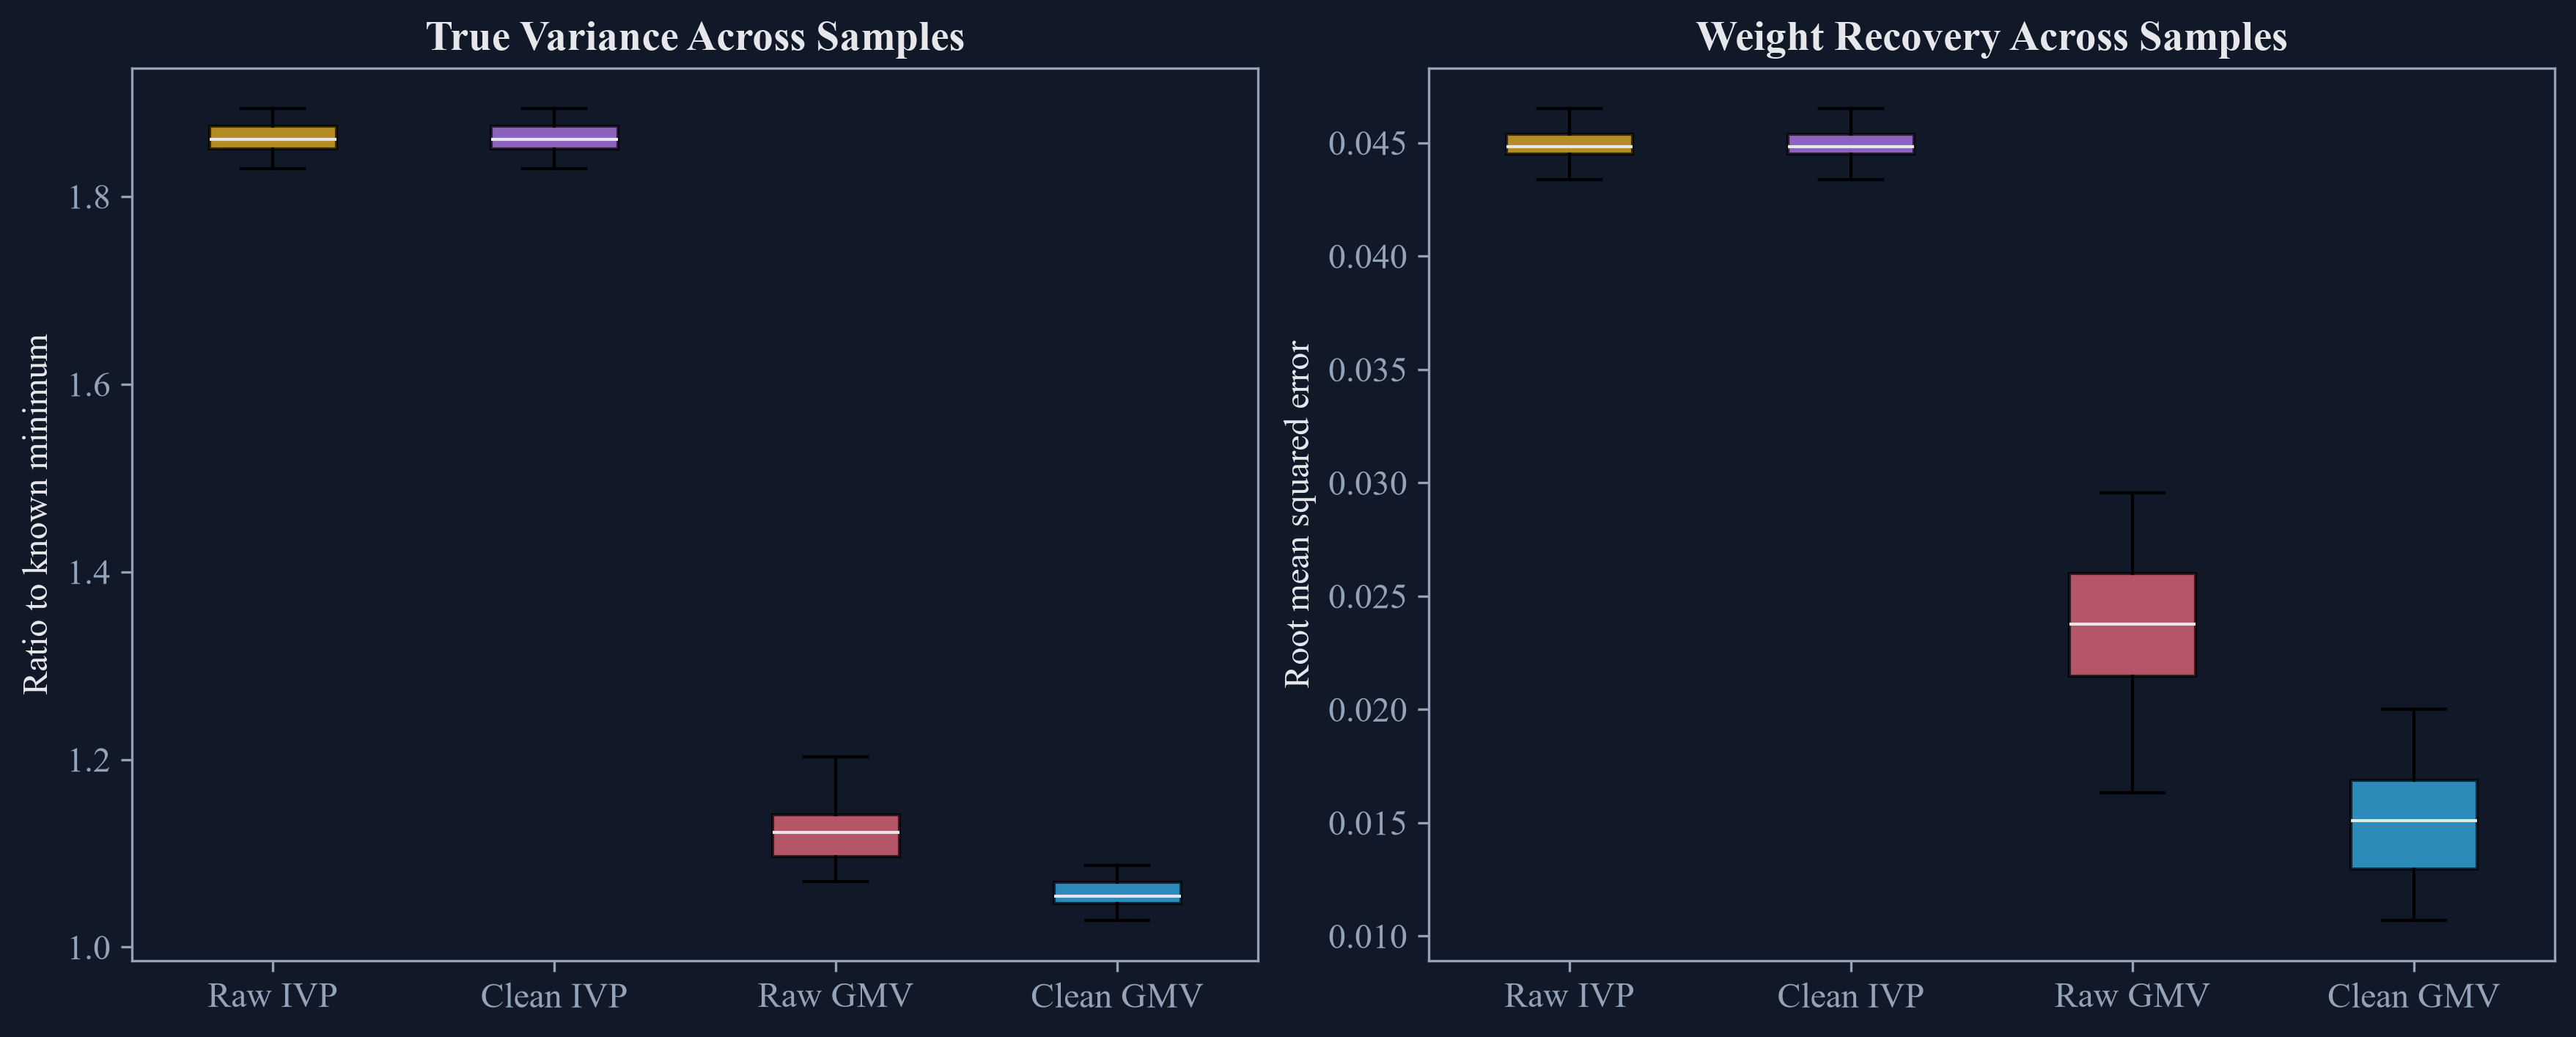

In [4]:
repetition_count = 40
repeated_rows = []
for repetition in range(repetition_count):
    np.random.seed(2000 + repetition)
    repeated_mean, repeated_covariance = simulates_cov_mu(true_mean, true_covariance, observation_count)
    repeated_cleaned = denoise_cov(repeated_covariance, observation_asset_ratio)
    method_weights = {
        "Raw inverse variance": inverse_variance(repeated_covariance),
        "Cleaned inverse variance": inverse_variance(repeated_cleaned),
        "Raw GMV": global_minimum_variance(repeated_covariance),
        "Cleaned GMV": global_minimum_variance(repeated_cleaned),
    }
    for method, weights in method_weights.items():
        repeated_rows.append({
            "Repetition": repetition + 1,
            "Method": method,
            "Weight root mean squared error": np.sqrt(np.mean((weights - true_gmv) ** 2)),
            "True variance ratio": float(weights @ true_covariance @ weights) / true_variance_floor,
            "Gross exposure": np.abs(weights).sum(),
        })
repeated_results = pd.DataFrame(repeated_rows)
repeated_summary_rows = []
for method, group in repeated_results.groupby("Method", sort=False):
    repeated_summary_rows.append({
        "Method": method,
        "Mean weight root mean squared error": group["Weight root mean squared error"].mean(),
        "Mean true variance ratio": group["True variance ratio"].mean(),
        "Median true variance ratio": group["True variance ratio"].median(),
        "True variance ratio standard error": group["True variance ratio"].std(ddof=1) / np.sqrt(repetition_count),
        "Mean gross exposure": group["Gross exposure"].mean(),
    })
repeated_summary = pd.DataFrame(repeated_summary_rows)
raw_gmv_ratios = repeated_results.loc[repeated_results["Method"] == "Raw GMV"].set_index("Repetition")["True variance ratio"]
cleaned_gmv_ratios = repeated_results.loc[repeated_results["Method"] == "Cleaned GMV"].set_index("Repetition")["True variance ratio"]
paired_summary = pd.DataFrame({
    "Quantity": ["Repetitions", "Cleaned GMV lower true variance", "Raw GMV mean true variance ratio", "Cleaned GMV mean true variance ratio", "Mean paired ratio difference"],
    "Value": [repetition_count, int((cleaned_gmv_ratios < raw_gmv_ratios).sum()), raw_gmv_ratios.mean(), cleaned_gmv_ratios.mean(), (cleaned_gmv_ratios - raw_gmv_ratios).mean()],
})
save_table(repeated_summary, "repeated_known_truth_summary", "Portfolio errors across forty controlled samples.", "tab:chapter20-repeated-summary")
save_table(paired_summary, "repeated_paired_summary", "Paired raw and cleaned GMV comparisons across controlled samples.", "tab:chapter20-repeated-paired")
display(repeated_summary.round(6))
display(paired_summary.round(6))

method_order = ["Raw inverse variance", "Cleaned inverse variance", "Raw GMV", "Cleaned GMV"]
short_labels = ["Raw IVP", "Clean IVP", "Raw GMV", "Clean GMV"]
colors = [palette["amber"], palette["violet"], palette["rose"], palette["cyan"]]
figure, axes = plt.subplots(1, 2, figsize=(11.6, 4.6), constrained_layout=True)
variance_plot = axes[0].boxplot([repeated_results.loc[repeated_results["Method"] == method, "True variance ratio"] for method in method_order], tick_labels=short_labels, patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
error_plot = axes[1].boxplot([repeated_results.loc[repeated_results["Method"] == method, "Weight root mean squared error"] for method in method_order], tick_labels=short_labels, patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
for patch, color in zip(variance_plot["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
for patch, color in zip(error_plot["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
axes[0].set_title("True Variance Across Samples")
axes[0].set_ylabel("Ratio to known minimum")
axes[1].set_title("Weight Recovery Across Samples")
axes[1].set_ylabel("Root mean squared error")
save_figure(figure, "repeated_known_truth_portfolios")

## Tests

In [5]:
assert true_covariance.shape == (30, 30)
assert sample_covariance.shape == (30, 30)
assert cleaned_covariance.shape == (30, 30)
assert np.linalg.eigvalsh(true_covariance).min() > 0.0
assert np.linalg.eigvalsh(sample_covariance).min() > 0.0
assert np.linalg.eigvalsh(cleaned_covariance).min() > 0.0
assert np.allclose(np.diag(true_correlation), 1.0)
assert np.allclose(np.diag(sample_correlation), 1.0)
assert np.allclose(np.diag(cleaned_correlation), 1.0)
assert np.isclose(true_gmv.sum(), 1.0)
assert np.isclose(raw_gmv.sum(), 1.0)
assert np.isclose(clean_gmv.sum(), 1.0)
assert np.isclose(raw_ivp.sum(), 1.0)
assert np.isclose(clean_ivp.sum(), 1.0)
assert true_variance_floor <= float(raw_gmv @ true_covariance @ raw_gmv) + 1e-12
assert true_variance_floor <= float(clean_gmv @ true_covariance @ clean_gmv) + 1e-12
assert covariance_sensitivity.iloc[0]["Weight absolute change"] < 1e-12
assert mean_sensitivity.iloc[0]["Weight absolute change"] < 1e-12
assert len(repeated_results) == repetition_count * 4
assert repeated_results.groupby("Method").size().eq(repetition_count).all()
assert repeated_results["True variance ratio"].ge(1.0 - 1e-10).all()
assert preliminary_reproduction["Chapter 20 result"].eq("Reproduced").all()
assert (FIGURES / "true_sample_cleaned_correlations.pdf").is_file()
assert (FIGURES / "one_path_weights_true_risk.pdf").is_file()
assert (FIGURES / "covariance_mean_sensitivity.pdf").is_file()
assert (FIGURES / "repeated_known_truth_portfolios.pdf").is_file()
assert (TABLES / "one_path_portfolio_summary.tex").is_file()
assert (TABLES / "repeated_known_truth_summary.tex").is_file()